P_3(1.5)  = 0.416667
P_10(1.5) = 0.405435
P_10(2.5) = -2.403097
Menor grado n con error < 1e-6 en x=1.5: n = 15 (error = 6.49e-07)


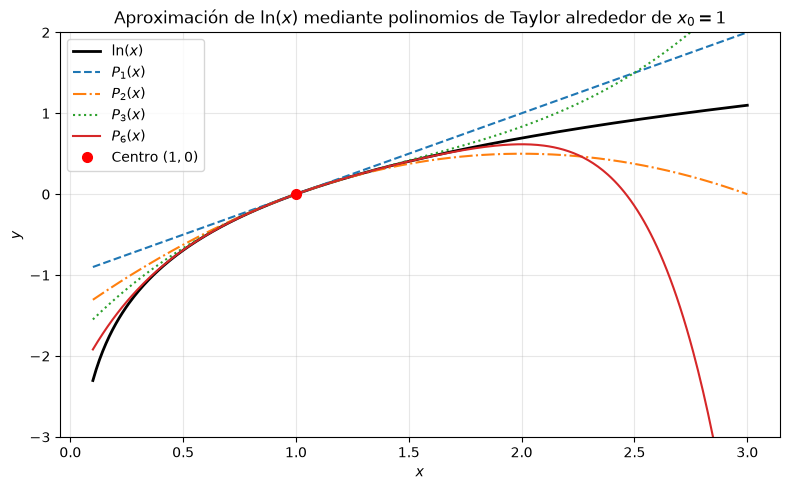

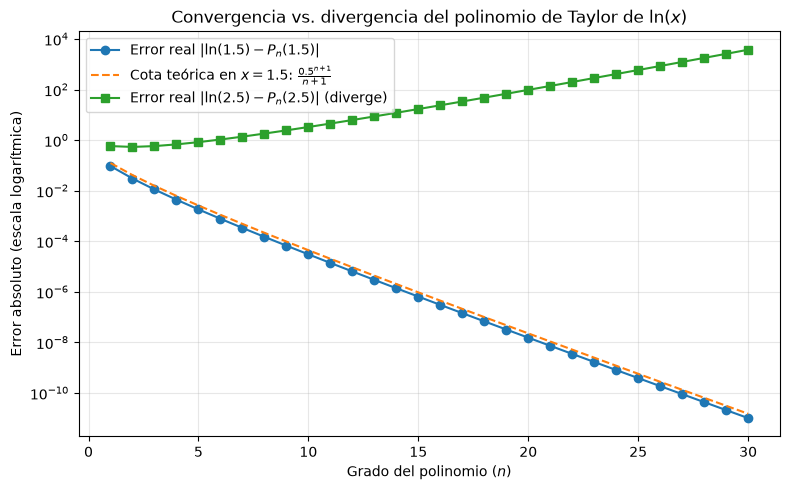

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def taylor_ln(x, n):
    """Polinomio de Taylor de grado n de ln(x) alrededor de x0 = 1"""
    suma = 0
    for k in range(1, n + 1):
        suma = suma + ((-1)**(k + 1) / k) * (x - 1)**k
    return suma

print(f"P_3(1.5)  = {taylor_ln(1.5, 3):.6f}")
print(f"P_10(1.5) = {taylor_ln(1.5, 10):.6f}")
print(f"P_10(2.5) = {taylor_ln(2.5, 10):.6f}")

for n in range(1, 31):
    err = abs(np.log(1.5) - taylor_ln(1.5, n))
    if err < 1e-6:
        print(f"Menor grado n con error < 1e-6 en x=1.5: n = {n} (error = {err:.2e})")
        break

x_vals = np.linspace(0.1, 3, 400)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, np.log(x_vals), 'k-', linewidth=2, label=r'$\ln(x)$')
for grado, estilo in zip([1, 2, 3, 6], ['--', '-.', ':', '-']):
    plt.plot(x_vals, taylor_ln(x_vals, grado), linestyle=estilo, label=f'$P_{grado}(x)$')

plt.plot(1, 0, 'ro', markersize=7, label='Centro $(1, 0)$')
plt.ylim(-3, 2)
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Aproximación de $\\ln(x)$ mediante polinomios de Taylor alrededor de $x_0 = 1$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('grafica_1_polinomios.png', dpi=300)
plt.show()

# --- 3. Gráfica 2: Error en escala logarítmica y cota ---
grados = np.arange(1, 31)
errores_15 = [abs(np.log(1.5) - taylor_ln(1.5, n)) for n in grados]
errores_25 = [abs(np.log(2.5) - taylor_ln(2.5, n)) for n in grados]
cota_15 = [(0.5**(n + 1)) / (n + 1) for n in grados]

plt.figure(figsize=(8, 5))
plt.semilogy(grados, errores_15, 'o-', label='Error real $|\\ln(1.5) - P_n(1.5)|$')
plt.semilogy(grados, cota_15, '--', label='Cota teórica en $x=1.5$: $\\frac{0.5^{n+1}}{n+1}$')
plt.semilogy(grados, errores_25, 's-', label='Error real $|\\ln(2.5) - P_n(2.5)|$ (diverge)')

plt.xlabel('Grado del polinomio ($n$)')
plt.ylabel('Error absoluto (escala logarítmica)')
plt.title('Convergencia vs. divergencia del polinomio de Taylor de $\\ln(x)$')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('grafica_2_errores.png', dpi=300)
plt.show()